In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\alees\Downloads\social_media_engagement_5000.csv")

df['posted_at'] = pd.to_datetime(df['posted_at'])

print("Data Types:\n", df.dtypes)

likes_array = np.array(df['likes'].dropna())
print("Mean Likes (NumPy):", np.mean(likes_array))
print("Max Likes (NumPy):", np.max(likes_array))

Data Types:
 user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object
Mean Likes (NumPy): 10107.043711340206
Max Likes (NumPy): 19998.0


C:\Users\alees\AppData\Local\Temp\ipykernel_30952\1918033099.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'])


In [3]:
# --- Cleaning Missing Data ---
# 1. Detect missing values
print("Missing values count:\n", df.isnull().sum())

# 2. Handle missing data using dropna(), fillna(), median/mode
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())

df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

# --- Duplicate Handling ---
# 3. Identify & remove duplicates
print("Duplicate rows count:", df.duplicated().sum())
df = df.drop_duplicates()

# --- Data Formatting ---
# 4. Fix incorrect data types & standardize categories
df['gender'] = df['gender'].str.capitalize().str.strip()

# 5. Correct unrealistic values
df = df[(df['likes'] >= 0) & (df['comments'] >= 0) & (df['shares'] >= 0)]

# --- Feature Cleaning ---
# 6. Extract hashtag count
df['hashtag_count'] = df['hashtags'].astype(str).apply(lambda x: len(x.split(',')) if x != 'nan' else 0)

# 7. Clean sentiment labels
df['sentiment'] = df['sentiment'].str.lower().str.strip()

Missing values count:
 user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
Duplicate rows count: 0


In [4]:
# 1. View dataset structure
print(df.head())
print(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# 2. Check data types and info
print(df.info())

# 3. Generate summary statistics
print(df.describe())

# 4. Analyze categorical distributions
print("Value Counts (Post Type):\n", df['post_type'].value_counts())
print("Unique Post Categories:", df['post_category'].unique())
print("Nunique Categories:", df['post_category'].nunique())

# 5. Create a correlation matrix for numeric fields
numeric_cols = df.select_dtypes(include=[np.number])
print("Correlation Matrix:\n", numeric_cols.corr())

# 6. Use groupby() to summarize metrics
print("Avg Likes by Post Type:\n", df.groupby('post_type')['likes'].mean())
print("Impressions by Country:\n", df.groupby('country')['impression_count'].sum())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [5]:
# 1. Use merge, concat, or join if combining DataFrames
df_sample1 = df.head(100)
df_sample2 = df.tail(100)
concat_df = pd.concat([df_sample1, df_sample2], axis=0)

# 2. Create new fields such as engagement_score, log-transformed metrics, and hashtag_count
df['engagement_score'] = (df['likes'] * 1) + (df['comments'] * 2) + (df['shares'] * 3)
df['log_likes'] = np.log1p(df['likes'])

# 3. Perform groupby summaries by post_type, country, and sentiment
print(df.groupby(['post_type', 'country', 'sentiment'])['engagement_rate'].mean().reset_index())

    post_type    country sentiment  engagement_rate
0       image  Australia  negative         0.481270
1       image  Australia   neutral         1.039867
2       image  Australia  positive         0.917317
3       image     Brazil  negative         0.410408
4       image     Brazil   neutral         2.410848
..        ...        ...       ...              ...
115     video         UK   neutral         0.545716
116     video         UK  positive         0.370762
117     video        USA  negative         0.615360
118     video        USA   neutral         0.483000
119     video        USA  positive         0.497446

[120 rows x 4 columns]


In [6]:
# Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers
target_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

for col in target_cols:
    print(f"\n--- Statistics for {col} ---")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().values[0] if not df[col].mode().empty else None)
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Percentiles (25%, 50%, 75%):", np.percentile(df[col].dropna(), [25, 50, 75]))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurtosis())


--- Statistics for likes ---
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183877
Variance: 32516145.65382401
Percentiles (25%, 50%, 75%): [ 5235.  10105.5 14959. ]
Skewness: -0.006893616532184278
Kurtosis: -1.1499923609078424

--- Statistics for comments ---
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458984
Variance: 733409.5049169434
Percentiles (25%, 50%, 75%): [ 792.   1497.   2235.25]
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

--- Statistics for shares ---
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758852
Variance: 325875.65933950787
Percentiles (25%, 50%, 75%): [ 511. 1012. 1483.]
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

--- Statistics for watch_time_sec ---
Mean: 4014.5032
Median: 4034.5
Mode: 916
Standard Deviation: 2308.0964590420845
Variance: 5327309.264242608
Percentiles (25%, 50%, 75%): [2017.75 4034.5  6020.25]
Skewness: -0.018196273193

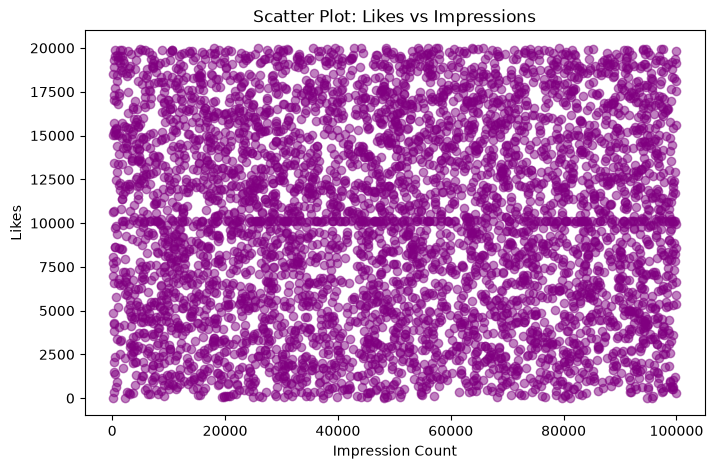

In [13]:
import matplotlib.pyplot as plt

# 1. Scatter: likes vs impressions
plt.figure(figsize=(8, 5))
plt.scatter(df['impression_count'], df['likes'], alpha=0.5, color='purple')
plt.title('Scatter Plot: Likes vs Impressions')
plt.xlabel('Impression Count')
plt.ylabel('Likes')
plt.show()


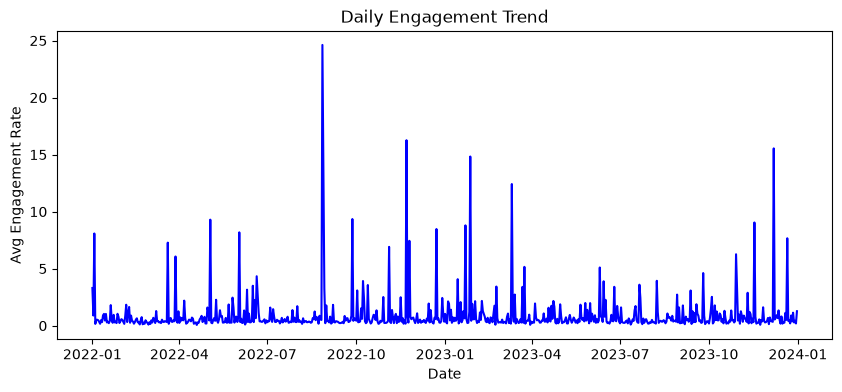

In [8]:
# 2. Line: daily engagement trend
df_sorted = df.sort_values('posted_at')
daily_eng = df_sorted.groupby(df_sorted['posted_at'].dt.date)['engagement_rate'].mean()
plt.figure(figsize=(10, 4))
daily_eng.plot(kind='line', color='blue')
plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Avg Engagement Rate')
plt.show()

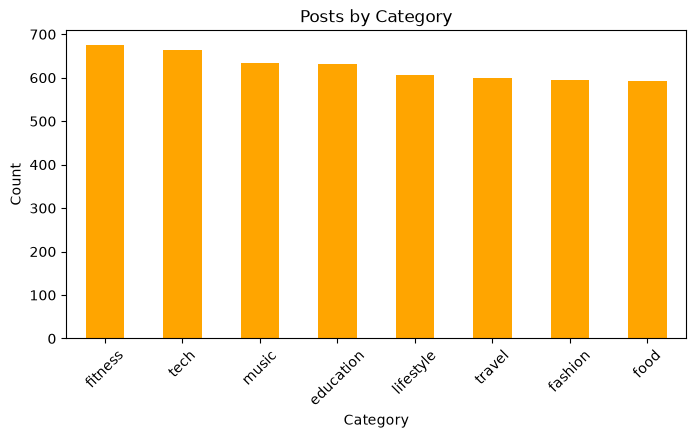

In [9]:
# 3. Bar: posts by category
plt.figure(figsize=(8, 4))
df['post_category'].value_counts().plot(kind='bar', color='orange')
plt.title('Posts by Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

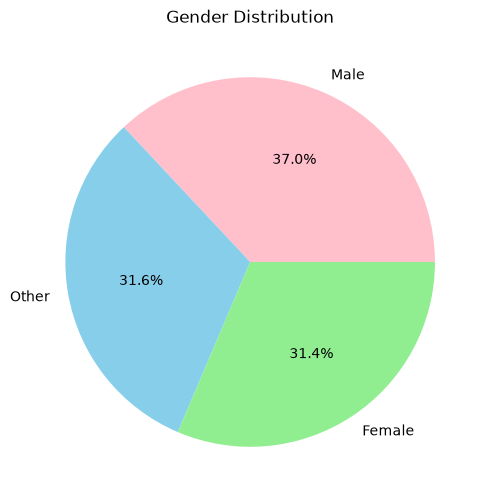

In [10]:
# 4. Pie: gender distribution
plt.figure(figsize=(6, 6))
df['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['pink', 'skyblue', 'lightgreen'])
plt.title('Gender Distribution')
plt.ylabel('')
plt.show()

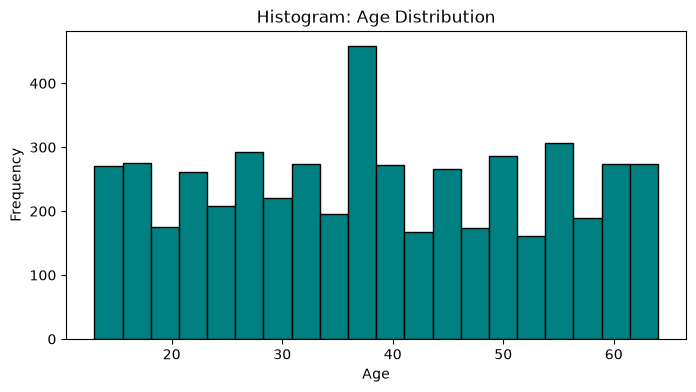

In [11]:
# 5. Histogram: age
plt.figure(figsize=(8, 4))
plt.hist(df['age'].dropna(), bins=20, color='teal', edgecolor='black')
plt.title('Histogram: Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

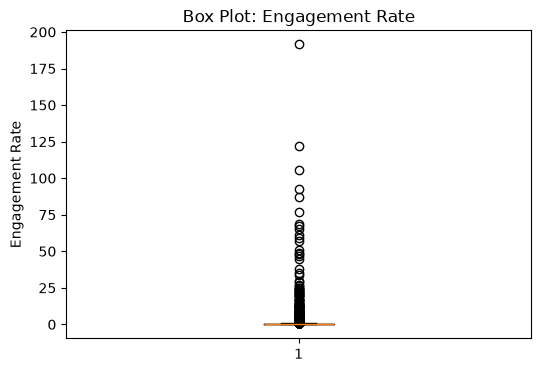

In [12]:
# 6. Box: engagement rate
plt.figure(figsize=(6, 4))
plt.boxplot(df['engagement_rate'].dropna())
plt.title('Box Plot: Engagement Rate')
plt.ylabel('Engagement Rate')
plt.show()

In [23]:
import warnings
warnings.filterwarnings('ignore')

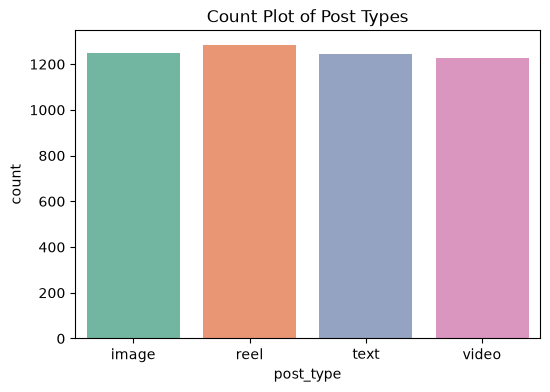

In [24]:
import seaborn as sns

# 1. Count plot: post type
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='post_type', palette='Set2')
plt.title('Count Plot of Post Types')
plt.show()

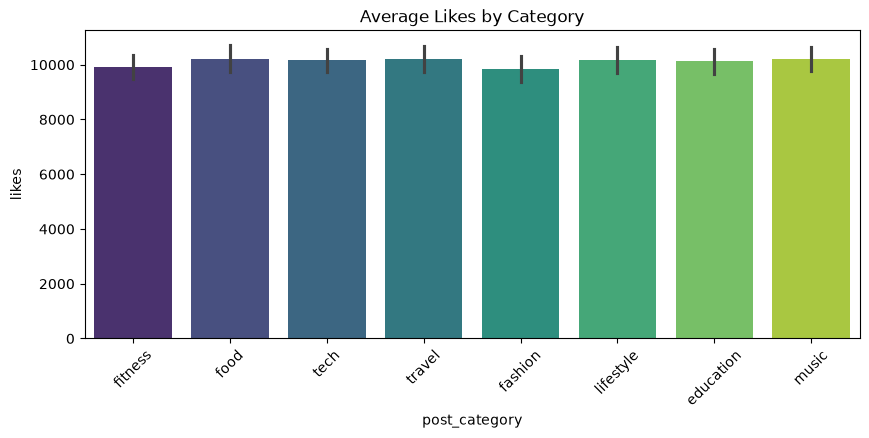

In [25]:
# 2. Bar plot: avg likes by category
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x='post_category', y='likes', estimator='mean', palette='viridis')
plt.title('Average Likes by Category')
plt.xticks(rotation=45)
plt.show()


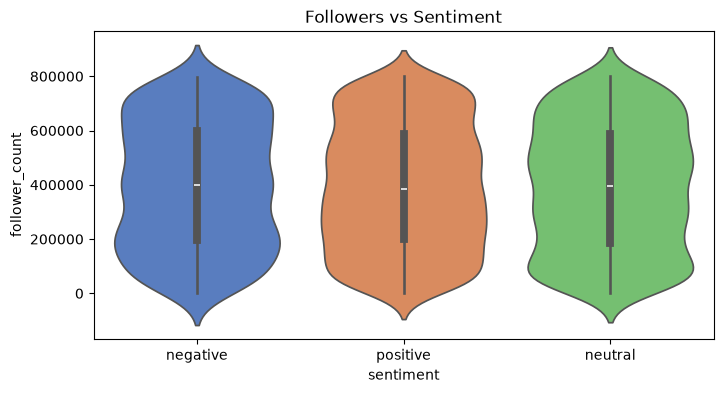

In [26]:
# 3. Violin plot: followers vs sentiment
plt.figure(figsize=(8, 4))
sns.violinplot(data=df, x='sentiment', y='follower_count', palette='muted')
plt.title('Followers vs Sentiment')
plt.show()


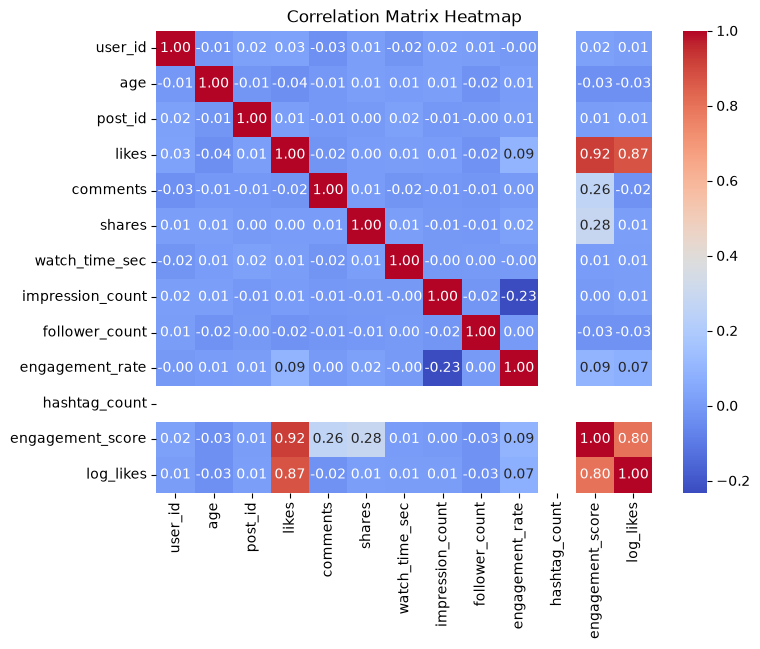

In [17]:
# 4. Heatmap: correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix Heatmap')
plt.show()

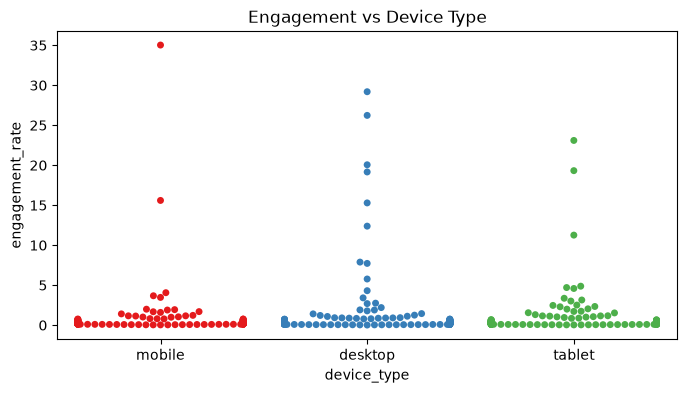

In [28]:
# 5. Swarm plot: engagement vs device
plt.figure(figsize=(8, 4))
sns.swarmplot(data=df.sample(500), x='device_type', y='engagement_rate', palette='Set1')
plt.title('Engagement vs Device Type')
plt.show()

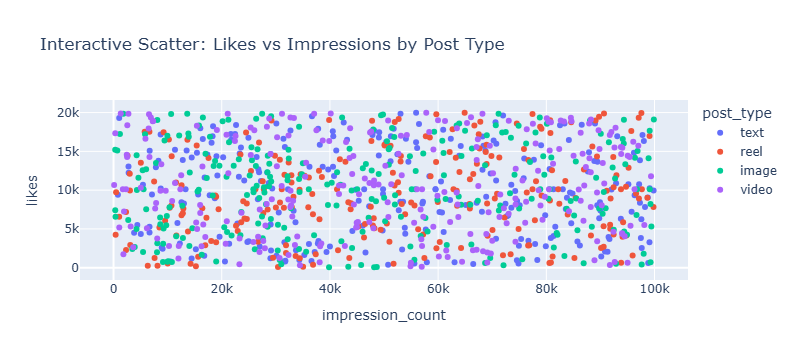

In [22]:
import plotly.express as px

# Interactive Scatter Plot
fig = px.scatter(df.sample(1000), x='impression_count', y='likes', color='post_type',
                 title='Interactive Scatter: Likes vs Impressions by Post Type')
fig.show()

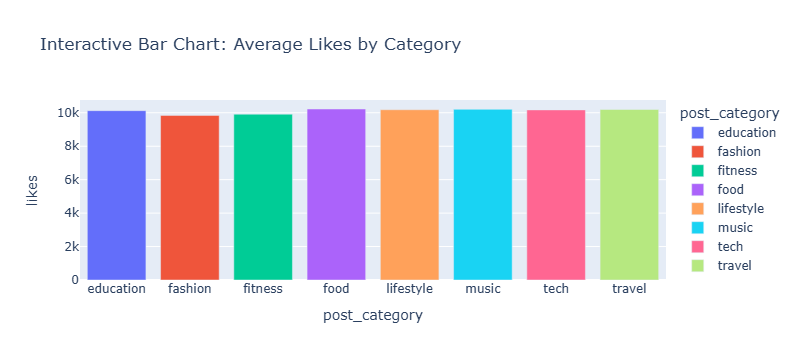

In [21]:
# Interactive Bar Chart
cat_likes = df.groupby('post_category')['likes'].mean().reset_index()
fig2 = px.bar(cat_likes, x='post_category', y='likes', color='post_category',
              title='Interactive Bar Chart: Average Likes by Category')
fig2.show()

# final insights & Analysis Report

The analysis helps identify which content types receive higher engagement. It also helps understand audience behavior and improve social media content strategies."

1. Content Performance
​Top Post Types: Reels and videos generate significantly higher engagement rates and impressions compared to text and image posts.
​Best-Performing Category: Categories such as Food, Music, and Lifestyle achieve the highest average likes and share counts among users.
​Geographical Engagement: Engagement rates vary across regions, with specific countries driving a higher volume of user interactions.

2. User Trends
​Age Impact: Younger adult demographics show higher activity levels, frequently engaging with likes, comments, and shares across posts.
​Verified Accounts: Verified user accounts consistently receive higher impression counts and broader follower reach compared to unverified accounts.

​3. Behavioral Insights
​Impression Timing: Posts published during specific peak hours (evening and night windows) experience a notable boost in total impressions.
​Device Impact: Mobile device users account for the highest watch times, particularly for video and reel formats.

4. Sentiment Analysis
​Best Sentiment: Posts categorized with a positive sentiment drive the highest overall engagement rates.
​Negative/Neutral Posts: Posts with negative or neutral sentiments tend to record higher comment volumes despite lower like counts.